In [12]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from pathlib import Path
 
import torch
import timm
import torchvision.transforms as transforms
 
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from xgboost import XGBClassifier
 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [13]:
# Configuration
BASE_DIR = Path("data/animals")

TRAIN_META = BASE_DIR / "train_metadata.csv"
TEST_META = BASE_DIR / "test_metadata.csv"
COLOR_HIST = BASE_DIR / "color_histogram.csv"
HOG_PCA = BASE_DIR / "hog_pca.csv"
ADDITIONAL_FEATS = BASE_DIR / "additional_features.csv"

TRAIN_EMB_CACHE = BASE_DIR / "train_vit_embeddings.npy"
TEST_EMB_CACHE = BASE_DIR / "test_vit_embeddings.npy"

SUBMISSION_PATH = BASE_DIR / "submission.csv"

BATCH_SIZE = 32
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")

Using device: cpu


In [14]:
# Load CSV Features
print("Loading CSV features...")
train_meta = pd.read_csv(TRAIN_META)
test_meta  = pd.read_csv(TEST_META)
 
color = pd.read_csv(COLOR_HIST)
hog = pd.read_csv(HOG_PCA)
add = pd.read_csv(ADDITIONAL_FEATS)
 
# Merge all features on image_id
def merge_features(meta, *feature_dfs):
    df = meta.copy()
    for fdf in feature_dfs:
        df = df.merge(fdf, on="image_id", how="left")
    return df
 
train_df = merge_features(train_meta, color, hog, add)
test_df  = merge_features(test_meta,  color, hog, add)
 
# Identify feature columns (everything except metadata cols)
meta_cols = ["image_id", "image_path", "class_id", "class_name"]
csv_feature_cols = [c for c in train_df.columns if c not in meta_cols]
 
print(f"Train samples: {len(train_df)}, Test samples: {len(test_df)}")
print(f"CSV feature dimensions: {len(csv_feature_cols)}")

Loading CSV features...
Train samples: 3750, Test samples: 1250
CSV feature dimensions: 219


In [15]:
# VIT Feature Extraction
def extract_vit_embeddings(image_ids, image_paths, base_dir, cache_path, batch_size=32):
    """
    Extract 384-dim embeddings from a pretrained ViT-Small/16 model.
    Results are cached to disk so re-running the script is fast.
    """
    if cache_path.exists():
        print(f"  Loading cached embeddings from {cache_path}")
        return np.load(cache_path)
 
    print(f"  Extracting ViT embeddings for {len(image_paths)} images...")
    print(f"  (Cached after first run)")
 
    # ViT-Small/16 pretrained on ImageNet-21k — generic features, not task-specific
    model = timm.create_model("vit_small_patch16_224", pretrained=True, num_classes=0)
    model.eval().to(DEVICE)
 
    preprocess = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225]),
    ])
 
    all_embeddings = []
 
    for i in range(0, len(image_paths), batch_size):
        batch_paths = image_paths[i : i + batch_size]
        imgs = []
        for rel_path in batch_paths:
            full_path = base_dir / rel_path
            try:
                img = Image.open(full_path).convert("RGB")
            except Exception:
                # If image missing, use a blank image rather than crash
                img = Image.new("RGB", (64, 64), (128, 128, 128))
            imgs.append(preprocess(img))
 
        batch_tensor = torch.stack(imgs).to(DEVICE)
        with torch.no_grad():
            emb = model(batch_tensor).cpu().numpy()
        all_embeddings.append(emb)
 
        if (i // batch_size) % 10 == 0:
            print(f"    Processed {min(i + batch_size, len(image_paths))}/{len(image_paths)}")
 
    embeddings = np.vstack(all_embeddings)
    np.save(cache_path, embeddings)
    print(f"  Saved embeddings to {cache_path}")
    return embeddings
 
 
print("\n--- Extracting ViT embeddings ---")
train_vit = extract_vit_embeddings(
    train_df["image_id"].values,
    train_df["image_path"].values,
    BASE_DIR,
    TRAIN_EMB_CACHE,
    BATCH_SIZE
)
test_vit = extract_vit_embeddings(
    test_df["image_id"].values,
    test_df["image_path"].values,
    BASE_DIR,
    TEST_EMB_CACHE,
    BATCH_SIZE
)
print(f"ViT embedding shape: {train_vit.shape}")


--- Extracting ViT embeddings ---
  Loading cached embeddings from data\animals\train_vit_embeddings.npy
  Loading cached embeddings from data\animals\test_vit_embeddings.npy
ViT embedding shape: (3750, 384)


In [5]:
# Combine Features and Normalise

# Raw CSV features
X_train_csv = train_df[csv_feature_cols].values.astype(np.float32)
X_test_csv  = test_df[csv_feature_cols].values.astype(np.float32)
 
# Fill any NaNs (shouldn't happen but just in case)
X_train_csv = np.nan_to_num(X_train_csv)
X_test_csv  = np.nan_to_num(X_test_csv)
 
# Standardise CSV features
scaler_csv = StandardScaler()
X_train_csv = scaler_csv.fit_transform(X_train_csv)
X_test_csv  = scaler_csv.transform(X_test_csv)
 
# Standardise ViT embeddings separately (they're already fairly well-scaled,
# but normalising helps SVM and LR converge faster)
scaler_vit = StandardScaler()
X_train_vit = scaler_vit.fit_transform(train_vit)
X_test_vit  = scaler_vit.transform(test_vit)
 
# Concatenate: [ViT embeddings | CSV features]
X_train = np.hstack([X_train_vit, X_train_csv])
X_test  = np.hstack([X_test_vit,  X_test_csv])
 
y_train = train_df["class_id"].values
 
print(f"Final feature vector size: {X_train.shape[1]}")
print(f"  ViT dims:  {X_train_vit.shape[1]}")
print(f"  CSV dims:  {X_train_csv.shape[1]}")

Final feature vector size: 603
  ViT dims:  384
  CSV dims:  219


In [6]:
# Cross Validation Helpers

def cv_evaluate(model, X, y, n_splits=5, label="Model"):
    """Stratified 5-fold cross-validation, prints mean ± std accuracy."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    scores = cross_val_score(model, X, y, cv=skf, scoring="accuracy", n_jobs=-1)
    print(f"  {label}: {scores.mean():.4f} ± {scores.std():.4f}  (folds: {np.round(scores, 4)})")
    return scores.mean()


In [7]:
# Model 1: Logistic Regression

print("\n--- Model 1: Logistic Regression ---")
 
lr = LogisticRegression(
    C=1.0,
    max_iter=1000,
    solver="lbfgs",
    random_state=42
)

lr_cv = cv_evaluate(lr, X_train, y_train, label="Logistic Regression")


--- Model 1: Logistic Regression ---
  Logistic Regression: 0.9245 ± 0.0111  (folds: [0.9067 0.9373 0.932  0.9293 0.9173])


In [8]:
# Model 2: SVM with RBF kernel

print("\n--- Model 2: SVM (RBF kernel) ---")

svm = SVC(
    C=10.0,
    kernel="rbf",
    gamma="scale",
    probability=True,
    random_state=42
)
svm_cv = cv_evaluate(svm, X_train, y_train, label="SVM RBF")


--- Model 2: SVM (RBF kernel) ---
  SVM RBF: 0.9264 ± 0.0111  (folds: [0.9147 0.9427 0.936  0.9227 0.916 ])


In [9]:
# Model 3: XGBoost
print("\n--- Model 3: XGBoost ---")

xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1,
    device="cpu" # use gpu if available
)
xgb_cv = cv_evaluate(xgb, X_train, y_train, label="XGBoost")


--- Model 3: XGBoost ---
  XGBoost: 0.9144 ± 0.0092  (folds: [0.9013 0.92   0.924  0.9213 0.9053])


In [10]:
# Pick best model and train on full data

print("\n--- Cross-validation summary ---")
results = {
    "Logistic Regression": lr_cv,
    "SVM RBF": svm_cv,
    "XGBoost": xgb_cv,
}
for name, score in sorted(results.items(), key=lambda x: -x[1]):
    print(f"  {name}: {score:.4f}")

best_name = max(results, key=results.get)
best_model = {"Logistic Regression": lr, "SVM RBF": svm, "XGBoost": xgb}[best_name]
print(f"\nBest model: {best_name} ({results[best_name]:.4f})")

# Fit best model on ALL training data
print(f"Fitting {best_name} on full training set...")
best_model.fit(X_train, y_train)

# Sanity check on training set (should be ~100% for SVM/XGB, lower for LR)
train_preds = best_model.predict(X_train)
print(f"Training accuracy (sanity check): {accuracy_score(y_train, train_preds):.4f}")


--- Cross-validation summary ---
  SVM RBF: 0.9264
  Logistic Regression: 0.9245
  XGBoost: 0.9144

Best model: SVM RBF (0.9264)
Fitting SVM RBF on full training set...
Training accuracy (sanity check): 1.0000



--- Generating confusion matrix on 20% holdout ---
Holdout validation accuracy: 0.9133


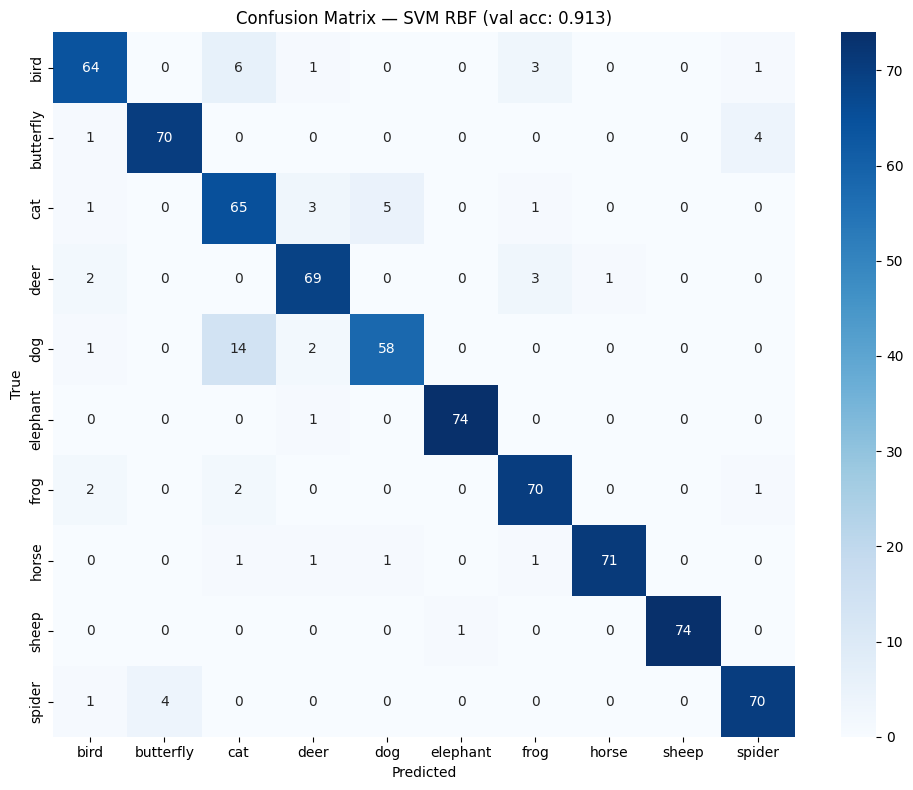

Saved: confusion_matrix.png

Classification Report:
              precision    recall  f1-score   support

        bird       0.89      0.85      0.87        75
   butterfly       0.95      0.93      0.94        75
         cat       0.74      0.87      0.80        75
        deer       0.90      0.92      0.91        75
         dog       0.91      0.77      0.83        75
    elephant       0.99      0.99      0.99        75
        frog       0.90      0.93      0.92        75
       horse       0.99      0.95      0.97        75
       sheep       1.00      0.99      0.99        75
      spider       0.92      0.93      0.93        75

    accuracy                           0.91       750
   macro avg       0.92      0.91      0.91       750
weighted avg       0.92      0.91      0.91       750



In [11]:
# Confusion Matrix
print("\n--- Generating confusion matrix on 20% holdout ---")
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42
)

# Train a fresh copy on 80%, evaluate on 20%
import copy
eval_model = copy.deepcopy(best_model)
eval_model.fit(X_tr, y_tr)
val_preds = eval_model.predict(X_val)
val_acc = accuracy_score(y_val, val_preds)
print(f"Holdout validation accuracy: {val_acc:.4f}")

# Class names in order of class_id (0-9)
class_names = (
    train_df[["class_id", "class_name"]]
    .drop_duplicates()
    .sort_values("class_id")["class_name"]
    .tolist()
)

cm = confusion_matrix(y_val, val_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names
)
plt.title(f"Confusion Matrix — {best_name} (val acc: {val_acc:.3f})")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(BASE_DIR / "confusion_matrix.png", dpi=150)
plt.show()
print("Saved: confusion_matrix.png")

print("\nClassification Report:")
print(classification_report(y_val, val_preds, target_names=class_names))